### Part A - Image Representation

In [1]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from pathlib import Path

zip_path = Path(r"D:\ML\202618023_Drashti_DS605\202618023_Lab_07\archive.zip")

print("ZIP file exists:", zip_path.exists())

if zip_path.exists():
    print("ZIP file size:", round(zip_path.stat().st_size / 1024, 2), "KB")

ZIP file exists: True
ZIP file size: 3693.09 KB


In [3]:
import zipfile
from pathlib import Path

extract_path = zip_path.parent / "ORL_Dataset"

extract_path.mkdir(exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Dataset location:", extract_path)

Dataset extracted successfully!
Dataset location: D:\ML\202618023_Drashti_DS605\202618023_Lab_07\ORL_Dataset


In [4]:
from pathlib import Path

dataset_path = Path(
    r"D:\ML\202618023_Drashti_DS605\202618023_Lab_07\ORL_Dataset"
)

for item in list(dataset_path.iterdir())[:15]:
    print(item.name)

README
s1
s10
s11
s12
s13
s14
s15
s16
s17
s18
s19
s2
s20
s21


In [6]:
from pathlib import Path

dataset_path = Path(
    r"D:\ML\202618023_Drashti_DS605\202618023_Lab_07\ORL_Dataset"
)

print("Dataset folder exists:", dataset_path.exists())
print("\nFiles and folders:")

for item in dataset_path.iterdir():
    print(item.name, "|", "Folder" if item.is_dir() else "File")

Dataset folder exists: True

Files and folders:
README | File
s1 | Folder
s10 | Folder
s11 | Folder
s12 | Folder
s13 | Folder
s14 | Folder
s15 | Folder
s16 | Folder
s17 | Folder
s18 | Folder
s19 | Folder
s2 | Folder
s20 | Folder
s21 | Folder
s22 | Folder
s23 | Folder
s24 | Folder
s25 | Folder
s26 | Folder
s27 | Folder
s28 | Folder
s29 | Folder
s3 | Folder
s30 | Folder
s31 | Folder
s32 | Folder
s33 | Folder
s34 | Folder
s35 | Folder
s36 | Folder
s37 | Folder
s38 | Folder
s39 | Folder
s4 | Folder
s40 | Folder
s5 | Folder
s6 | Folder
s7 | Folder
s8 | Folder
s9 | Folder


In [7]:
from pathlib import Path

dataset_path = Path(
    r"D:\ML\202618023_Drashti_DS605\202618023_Lab_07\ORL_Dataset"
)

subject_folders = sorted(
    [folder for folder in dataset_path.iterdir()
     if folder.is_dir() and folder.name.startswith("s")],
    key=lambda folder: int(folder.name[1:])
)

print("Total subjects:", len(subject_folders))

for folder in subject_folders[:5]:
    print(folder.name, ":", len(list(folder.iterdir())), "files")

Total subjects: 40
s1 : 10 files
s2 : 10 files
s3 : 10 files
s4 : 10 files
s5 : 10 files


In [8]:
from PIL import Image
import numpy as np

images = []
labels = []

for subject_folder in subject_folders:
    image_files = sorted(subject_folder.iterdir())

    for image_file in image_files:
        if image_file.suffix.lower() not in {".pgm", ".png", ".jpg", ".jpeg"}:
            continue

        image = Image.open(image_file).convert("L")
        image_matrix = np.array(image)

        image_vector = image_matrix.flatten()

        images.append(image_vector)
        labels.append(subject_folder.name)

X = np.array(images)
y = np.array(labels)

print("Image matrix shape:", X.shape)
print("Labels shape:", y.shape)
print("Number of images:", len(X))
print("Number of subjects:", len(np.unique(y)))

Image matrix shape: (400, 10304)
Labels shape: (400,)
Number of images: 400
Number of subjects: 40


Check the first image

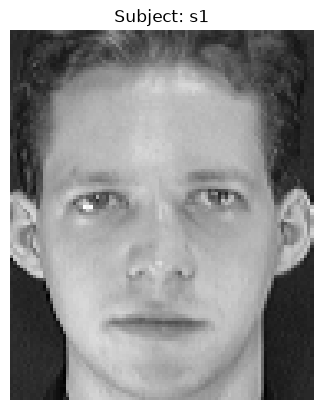

In [9]:
import matplotlib.pyplot as plt

plt.imshow(X[0].reshape(image_matrix.shape), cmap="gray")
plt.title(f"Subject: {y[0]}")
plt.axis("off")
plt.show()

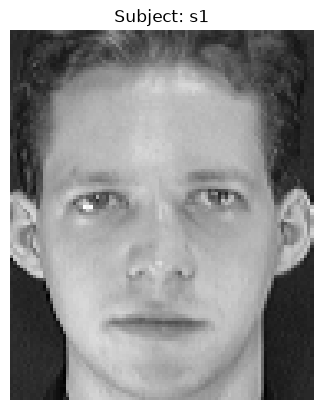

In [10]:
image_height, image_width = Image.open(
    next(subject_folders[0].iterdir())
).convert("L").size[::-1]

plt.imshow(X[0].reshape(image_height, image_width), cmap="gray")
plt.title(f"Subject: {y[0]}")
plt.axis("off")
plt.show()

In [11]:
print(X.shape)
print(y.shape)

(400, 10304)
(400,)


In [12]:
image_vector = image_matrix.flatten()

print("Original shape:", image_matrix.shape)
print("Flattened shape:", image_vector.shape)
print("First 10 pixel values:", image_vector[:10])

Original shape: (112, 92)
Flattened shape: (10304,)
First 10 pixel values: [119 120 120 118 120 121 121 116 120 121]


Train-Test Split

In [13]:
import numpy as np

rng = np.random.default_rng(42)

train_indices = []
test_indices = []

test_ratio = 0.20

for subject in np.unique(y):

    subject_indices = np.where(y == subject)[0]

    subject_indices = rng.permutation(subject_indices)

    n_test = max(1, int(round(len(subject_indices) * test_ratio)))

    test_indices.extend(subject_indices[:n_test])
    train_indices.extend(subject_indices[n_test:])

train_indices = np.array(train_indices)
test_indices = np.array(test_indices)

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices]
y_test = y[test_indices]

print("Training images:", X_train.shape[0])
print("Testing images:", X_test.shape[0])

print("Training matrix shape:", X_train.shape)
print("Testing matrix shape:", X_test.shape)

Training images: 320
Testing images: 80
Training matrix shape: (320, 10304)
Testing matrix shape: (80, 10304)


In [14]:
train_subjects = set(y_train)
test_subjects = set(y_test)

print("Subjects in training:", len(train_subjects))
print("Subjects in testing:", len(test_subjects))

print("Subjects missing from training:", set(np.unique(y)) - train_subjects)
print("Subjects missing from testing:", set(np.unique(y)) - test_subjects)

Subjects in training: 40
Subjects in testing: 40
Subjects missing from training: set()
Subjects missing from testing: set()


In [15]:
for subject in np.unique(y):
    print(
        subject,
        "| Training:", np.sum(y_train == subject),
        "| Testing:", np.sum(y_test == subject)
    )

s1 | Training: 8 | Testing: 2
s10 | Training: 8 | Testing: 2
s11 | Training: 8 | Testing: 2
s12 | Training: 8 | Testing: 2
s13 | Training: 8 | Testing: 2
s14 | Training: 8 | Testing: 2
s15 | Training: 8 | Testing: 2
s16 | Training: 8 | Testing: 2
s17 | Training: 8 | Testing: 2
s18 | Training: 8 | Testing: 2
s19 | Training: 8 | Testing: 2
s2 | Training: 8 | Testing: 2
s20 | Training: 8 | Testing: 2
s21 | Training: 8 | Testing: 2
s22 | Training: 8 | Testing: 2
s23 | Training: 8 | Testing: 2
s24 | Training: 8 | Testing: 2
s25 | Training: 8 | Testing: 2
s26 | Training: 8 | Testing: 2
s27 | Training: 8 | Testing: 2
s28 | Training: 8 | Testing: 2
s29 | Training: 8 | Testing: 2
s3 | Training: 8 | Testing: 2
s30 | Training: 8 | Testing: 2
s31 | Training: 8 | Testing: 2
s32 | Training: 8 | Testing: 2
s33 | Training: 8 | Testing: 2
s34 | Training: 8 | Testing: 2
s35 | Training: 8 | Testing: 2
s36 | Training: 8 | Testing: 2
s37 | Training: 8 | Testing: 2
s38 | Training: 8 | Testing: 2
s39 | Train

### Part B - PCA, Eigenfaces and Compression

Mean Face and Mean Centering

In [16]:
import numpy as np
import matplotlib.pyplot as plt

mean_face = np.mean(X_train, axis=0)

print("Training matrix shape:", X_train.shape)
print("Mean face shape:", mean_face.shape)

Training matrix shape: (320, 10304)
Mean face shape: (10304,)


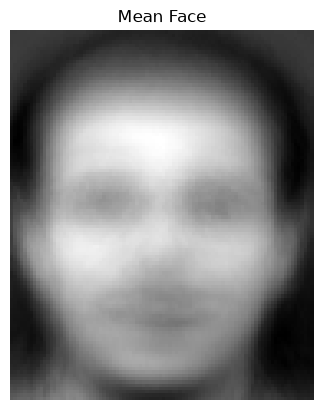

In [17]:
image_height, image_width = 112, 92

plt.imshow(
    mean_face.reshape(image_height, image_width),
    cmap="gray"
)

plt.title("Mean Face")
plt.axis("off")
plt.show()

In [18]:
X_train_centered = X_train - mean_face

print("Centered training matrix:", X_train_centered.shape)
print("Mean of centered features:", np.mean(X_train_centered, axis=0)[:10])

Centered training matrix: (320, 10304)
Mean of centered features: [ 0.00000000e+00 -2.77999845e-14 -2.77999845e-14 -2.77555756e-14
  9.41469125e-15  2.77555756e-14  1.02140518e-14  0.00000000e+00
  0.00000000e+00  1.05693232e-14]


In [19]:
X_test_centered = X_test - mean_face

print("Centered test matrix:", X_test_centered.shape)

Centered test matrix: (80, 10304)


PCA Using Covariance Matrix and Eigendecomposition

In [20]:
import numpy as np

n_samples = X_train_centered.shape[0]

covariance_matrix = (
    X_train_centered.T @ X_train_centered
) / (n_samples - 1)

print("Covariance matrix shape:", covariance_matrix.shape)

Covariance matrix shape: (10304, 10304)


In [21]:
#Calculate eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(covariance_matrix)

print("Eigenvalues shape:", eigenvalues.shape)
print("Eigenvectors shape:", eigenvectors.shape)

Eigenvalues shape: (10304,)
Eigenvectors shape: (10304, 10304)


In [22]:
#Sort eigenvalues and eigenvectors

sorted_indices = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[sorted_indices]
eigenvectors = eigenvectors[:, sorted_indices]

print("Largest eigenvalues:", eigenvalues[:5])

Largest eigenvalues: [2849697.33223255 2041046.86090865 1079582.06024308  895968.90775829
  806095.51460974]


In [23]:
#Check the explained variance

total_variance = np.sum(eigenvalues)

explained_variance_ratio = eigenvalues / total_variance

cumulative_variance = np.cumsum(explained_variance_ratio)

print("First 10 explained variance ratios:")
print(explained_variance_ratio[:10])

print("\nCumulative variance after 10 components:")
print(cumulative_variance[9])

First 10 explained variance ratios:
[0.17854809 0.12788201 0.06764133 0.05613703 0.050506   0.03383515
 0.02480714 0.0239824  0.02020048 0.01805509]

Cumulative variance after 10 components:
0.601594703884066


PCA Using Singular Value Decomposition (SVD)

In [24]:
#Calculate SVD



import numpy as np

U, singular_values, VT = np.linalg.svd(
    X_train_centered,
    full_matrices=False
)

print("U shape:", U.shape)
print("Singular values shape:", singular_values.shape)
print("VT shape:", VT.shape)

U shape: (320, 320)
Singular values shape: (320,)
VT shape: (320, 10304)


In [25]:
#Calculate explained variance
eigenvalues_svd = singular_values**2 / (
    X_train_centered.shape[0] - 1
)

explained_variance_ratio_svd = (
    eigenvalues_svd / np.sum(eigenvalues_svd)
)

cumulative_variance_svd = np.cumsum(
    explained_variance_ratio_svd
)

print("First 10 explained variance ratios:")
print(explained_variance_ratio_svd[:10])

print(
    "Cumulative variance after 10 components:",
    cumulative_variance_svd[9]
)

First 10 explained variance ratios:
[0.17854809 0.12788201 0.06764133 0.05613703 0.050506   0.03383515
 0.02480714 0.0239824  0.02020048 0.01805509]
Cumulative variance after 10 components: 0.601594703884065


In [26]:
#Extract the principal components
principal_components = VT.T

print("Principal components shape:", principal_components.shape)

Principal components shape: (10304, 320)


In [27]:
m = 50

components_m = principal_components[:, :m]

print("Selected components shape:", components_m.shape)

Selected components shape: (10304, 50)


The resulting shape is:

$$ 10304\times50 $$

Each image can now be represented using 50 PCA features rather than 10,304 original pixel features.

The choice of 50 here is only an example. Later, we will determine how many components are needed to preserve at least 90% of the variance.

In [28]:
#Project faces into PCA space

X_train_pca = X_train_centered @ components_m

print("Original training shape:", X_train.shape)
print("Reduced training shape:", X_train_pca.shape)

Original training shape: (320, 10304)
Reduced training shape: (320, 50)


Covariance-based PCA calculates the covariance matrix first and then finds its eigenvalues and eigenvectors. However, the covariance matrix can require substantial memory when the number of features is large.
SVD-based PCA decomposes the centered data matrix directly into \(U\), \(\Sigma\), and \(V^T\), avoiding the need to explicitly construct the large covariance matrix.
Both methods identify principal components and calculate explained variance, but SVD is often more numerically stable.
For high-dimensional face images, SVD is generally more practical because it avoids constructing a large covariance matrix.

Cumulative Explained Variance and Selecting 90% Variance

Components needed for 90% variance: 99
Variance preserved: 0.9008972004876585


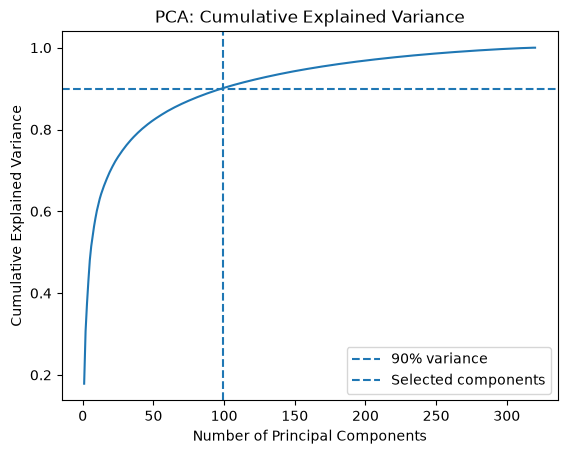

In [29]:
import numpy as np
import matplotlib.pyplot as plt

explained_variance_ratio = (
    singular_values**2 / np.sum(singular_values**2)
)

cumulative_variance = np.cumsum(explained_variance_ratio)

n_components = np.argmax(cumulative_variance >= 0.90) + 1

print("Components needed for 90% variance:", n_components)
print("Variance preserved:", cumulative_variance[n_components - 1])

plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance)
plt.axhline(y=0.90, linestyle="--", label="90% variance")
plt.axvline(x=n_components, linestyle="--", label="Selected components")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA: Cumulative Explained Variance")
plt.legend()
plt.show()

Visualizing Eigenfaces

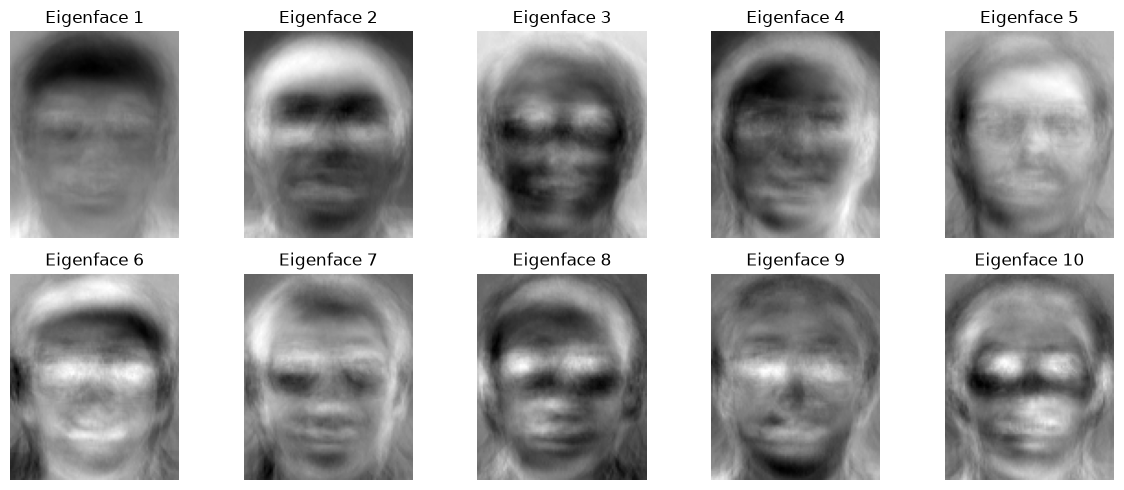

In [30]:
import matplotlib.pyplot as plt

n_eigenfaces = 10

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    eigenface = VT[i].reshape(image_height, image_width)
    ax.imshow(eigenface, cmap="gray")
    ax.set_title(f"Eigenface {i + 1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

Face Reconstruction Using PCA

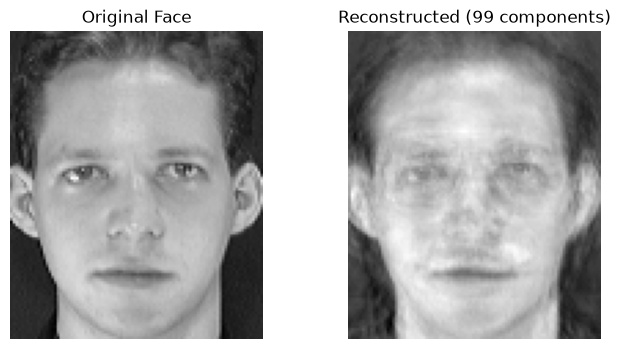

In [31]:
m = n_components  # Number selected to preserve 90% variance

components = VT[:m].T

z = X_train_centered[0] @ components
reconstructed_face = mean_face + z @ components.T

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(X_train[0].reshape(image_height, image_width), cmap="gray")
plt.title("Original Face")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(reconstructed_face.reshape(image_height, image_width), cmap="gray")
plt.title(f"Reconstructed ({m} components)")
plt.axis("off")

plt.show()

Reconstruction Error and Storage Comparison

In [32]:
original = X_train[0]
reconstructed = reconstructed_face

mse = np.mean((original - reconstructed) ** 2)

print("Reconstruction MSE:", mse)

Reconstruction MSE: 160.61211770386817


### Part C - Recognition in PCA Space

Face Recognition Using Euclidean Distance

In [34]:
print("X_train_centered:", X_train_centered.shape)
print("X_test_centered:", X_test_centered.shape)
print("components:", components.shape)
print("X_train_pca:", X_train_pca.shape)

X_train_centered: (320, 10304)
X_test_centered: (80, 10304)
components: (10304, 99)
X_train_pca: (320, 50)


In [35]:
# Recalculate training and testing representations using the same components
X_train_pca = X_train_centered @ components
X_test_pca = X_test_centered @ components

print("Training PCA shape:", X_train_pca.shape)
print("Testing PCA shape:", X_test_pca.shape)

# Nearest-neighbor recognition
predictions = []

for test_face in X_test_pca:
    distances = np.sqrt(
        np.sum((X_train_pca - test_face) ** 2, axis=1)
    )

    nearest_index = np.argmin(distances)
    predictions.append(y_train[nearest_index])

predictions = np.array(predictions)

accuracy = np.mean(predictions == y_test)

print(f"Recognition accuracy: {accuracy * 100:.2f}%")

Training PCA shape: (320, 99)
Testing PCA shape: (80, 99)
Recognition accuracy: 98.75%


Compare Raw Pixels vs PCA Features

In [36]:
# Raw-pixel nearest-neighbor recognition
raw_predictions = []

for test_face in X_test_centered:
    distances = np.sqrt(
        np.sum((X_train_centered - test_face) ** 2, axis=1)
    )

    nearest_index = np.argmin(distances)
    raw_predictions.append(y_train[nearest_index])

raw_predictions = np.array(raw_predictions)

raw_accuracy = np.mean(raw_predictions == y_test)

print(f"Raw-pixel accuracy: {raw_accuracy * 100:.2f}%")
print(f"PCA accuracy:       {accuracy * 100:.2f}%")
print(f"PCA components:     {components.shape[1]}")

Raw-pixel accuracy: 98.75%
PCA accuracy:       98.75%
PCA components:     99


Both methods correctly recognized 79 out of 80 test images.
PCA reduced the representation from 10,304 pixel features to just 99 components while maintaining the same recognition accuracy.
This demonstrates that dimensionality reduction can significantly reduce the number of features without reducing recognition accuracy on this test set.

### Part D - Traditional Machine Learning

K-Nearest Neighbors (KNN)

In [39]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

knn = KNeighborsClassifier(n_neighbors=3)
knn


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None


In [40]:
knn.fit(X_train_pca, y_train)

knn_predictions = knn.predict(X_test_pca)

knn_accuracy = accuracy_score(y_test, knn_predictions)

print(f"KNN Accuracy: {knn_accuracy * 100:.2f}%")

KNN Accuracy: 92.50%


Nearest-neighbor baseline: 98.75% (79/80 correct).
KNN with 3 neighbors: 92.50% (74/80 correct).
KNN considers three neighbors and predicts the majority class, whereas your baseline uses only the single closest training face.
Using more neighbors does not always improve accuracy; the best value depends on the dataset

Logistic Regression

In [43]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

lr = LogisticRegression(max_iter=2000)

lr

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [44]:
lr.fit(X_train_pca, y_train)

lr_predictions = lr.predict(X_test_pca)

lr_accuracy = accuracy_score(y_test, lr_predictions)

print(f"Logistic Regression Accuracy: {lr_accuracy * 100:.2f}%")

Logistic Regression Accuracy: 100.00%


In [45]:
import pandas as pd

results = pd.DataFrame({
    "Method": [
        "Nearest Neighbor - Raw Pixels",
        "Nearest Neighbor - PCA",
        "KNN - PCA (k=3)",
        "Logistic Regression - PCA"
    ],
    "Accuracy (%)": [
        raw_accuracy * 100,
        accuracy * 100,
        knn_accuracy * 100,
        lr_accuracy * 100
    ]
})

print(results.to_string(index=False))

                       Method  Accuracy (%)
Nearest Neighbor - Raw Pixels         98.75
       Nearest Neighbor - PCA         98.75
              KNN - PCA (k=3)         92.50
    Logistic Regression - PCA        100.00


Inspecting Correct and Incorrect Face Matches

Correct predictions: 79
Incorrect predictions: 1


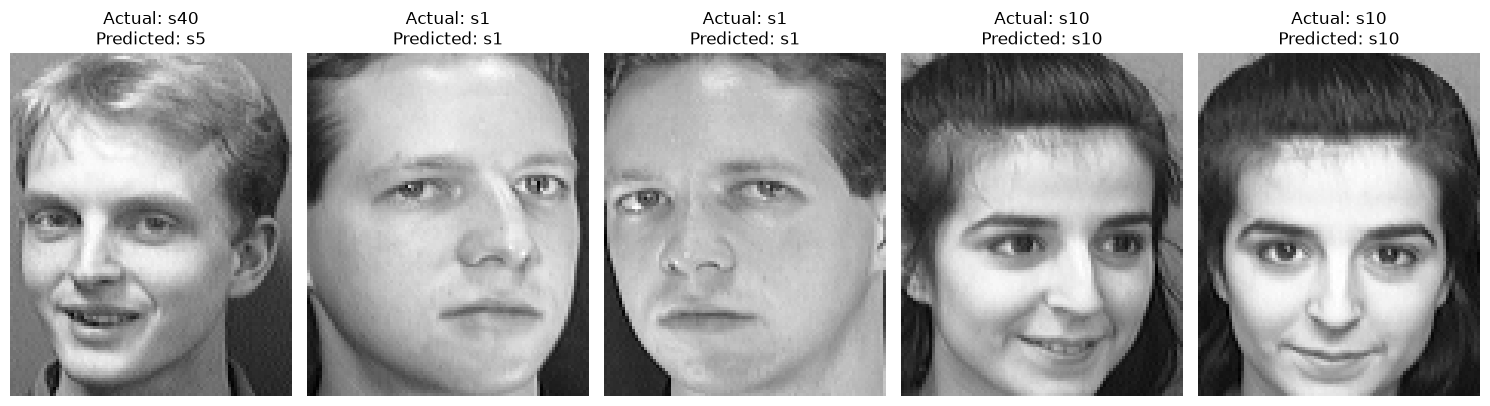

In [46]:
import matplotlib.pyplot as plt
import numpy as np

correct_indices = np.where(predictions == y_test)[0]
incorrect_indices = np.where(predictions != y_test)[0]

print("Correct predictions:", len(correct_indices))
print("Incorrect predictions:", len(incorrect_indices))

indices_to_show = list(incorrect_indices[:5])

if len(indices_to_show) < 5:
    indices_to_show += list(correct_indices[:5 - len(indices_to_show)])

fig, axes = plt.subplots(1, len(indices_to_show), figsize=(15, 4))

for ax, idx in zip(np.atleast_1d(axes), indices_to_show):
    ax.imshow(X_test[idx].reshape(image_height, image_width), cmap="gray")
    ax.set_title(
        f"Actual: {y_test[idx]}\nPredicted: {predictions[idx]}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

Experimenting with PCA Components and Tuning KNN

In [47]:
from sklearn.neighbors import KNeighborsClassifier
import numpy as np

for m in [50, 75, 99, 125]:
    if m > len(singular_values):
        continue

    components_m = VT[:m].T

    train_pca = X_train_centered @ components_m
    test_pca = X_test_centered @ components_m

    predictions_m = []

    for test_face in test_pca:
        distances = np.sum((train_pca - test_face) ** 2, axis=1)
        nearest_index = np.argmin(distances)
        predictions_m.append(y_train[nearest_index])

    accuracy_m = np.mean(np.array(predictions_m) == y_test)

    print(f"Components: {m}, Accuracy: {accuracy_m * 100:.2f}%")

Components: 50, Accuracy: 100.00%
Components: 75, Accuracy: 98.75%
Components: 99, Accuracy: 98.75%
Components: 125, Accuracy: 98.75%


In [48]:
import numpy as np

rng = np.random.default_rng(42)

fit_indices = []
val_indices = []

for subject in np.unique(y_train):
    indices = np.where(y_train == subject)[0]
    indices = rng.permutation(indices)

    n_val = max(1, int(round(len(indices) * 0.20)))

    val_indices.extend(indices[:n_val])
    fit_indices.extend(indices[n_val:])

X_fit = X_train_centered[fit_indices]
X_val = X_train_centered[val_indices]

y_fit = y_train[fit_indices]
y_val = y_train[val_indices]

print("Fit set:", X_fit.shape)
print("Validation set:", X_val.shape)

Fit set: (240, 10304)
Validation set: (80, 10304)


In [50]:
import numpy as np

# Calculate mean using only the fitting data
fit_mean = X_fit.mean(axis=0)

# Center fitting and validation data using the fitting mean
X_fit_centered = X_fit - fit_mean
X_val_centered = X_val - fit_mean

# Perform SVD using fitting data only
U_fit, S_fit, VT_fit = np.linalg.svd(
    X_fit_centered,
    full_matrices=False
)

# Select 99 components, or fewer if unavailable
m = min(99, len(S_fit))
components_fit = VT_fit[:m].T

# Project both datasets using the same components
X_fit_pca = X_fit_centered @ components_fit
X_val_pca = X_val_centered @ components_fit

print("Fitting PCA shape:", X_fit_pca.shape)
print("Validation PCA shape:", X_val_pca.shape)

Fitting PCA shape: (240, 99)
Validation PCA shape: (80, 99)


In [51]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

results = []

for k in [1, 3, 5, 7]:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_fit_pca, y_fit)

    val_predictions = knn.predict(X_val_pca)
    val_accuracy = accuracy_score(y_val, val_predictions)

    results.append((k, val_accuracy))

    print(f"k={k}: Validation accuracy = {val_accuracy * 100:.2f}%")

best_k, best_accuracy = max(results, key=lambda item: item[1])

print(f"\nBest k: {best_k}")
print(f"Best validation accuracy: {best_accuracy * 100:.2f}%")

k=1: Validation accuracy = 92.50%
k=3: Validation accuracy = 91.25%
k=5: Validation accuracy = 87.50%
k=7: Validation accuracy = 81.25%

Best k: 1
Best validation accuracy: 92.50%


In [52]:
import numpy as np
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

component_counts = [50, 75, 99, 125]
k_values = [1, 3, 5, 7, 9]

results = []

for m in component_counts:

    # Fit PCA using only the fitting data
    fit_mean = X_fit.mean(axis=0)

    X_fit_centered = X_fit - fit_mean
    X_val_centered = X_val - fit_mean

    _, singular_values_fit, VT_fit = np.linalg.svd(
        X_fit_centered,
        full_matrices=False
    )

    if m > len(singular_values_fit):
        print(f"Skipping {m} components: not available.")
        continue

    components_fit = VT_fit[:m].T

    X_fit_pca = X_fit_centered @ components_fit
    X_val_pca = X_val_centered @ components_fit

    # Tune KNN for this component count
    for k in k_values:

        knn = KNeighborsClassifier(n_neighbors=k)
        knn.fit(X_fit_pca, y_fit)

        val_predictions = knn.predict(X_val_pca)

        val_accuracy = accuracy_score(
            y_val,
            val_predictions
        )

        results.append({
            "Components": m,
            "K": k,
            "Validation Accuracy (%)": round(
                val_accuracy * 100, 2
            )
        })

        print(
            f"Components: {m:3d} | "
            f"k: {k} | "
            f"Accuracy: {val_accuracy * 100:.2f}%"
        )

results_df = pd.DataFrame(results)

print("\nComplete Results:")
print(results_df.to_string(index=False))

Components:  50 | k: 1 | Accuracy: 93.75%
Components:  50 | k: 3 | Accuracy: 91.25%
Components:  50 | k: 5 | Accuracy: 88.75%
Components:  50 | k: 7 | Accuracy: 81.25%
Components:  50 | k: 9 | Accuracy: 75.00%
Components:  75 | k: 1 | Accuracy: 91.25%
Components:  75 | k: 3 | Accuracy: 91.25%
Components:  75 | k: 5 | Accuracy: 87.50%
Components:  75 | k: 7 | Accuracy: 82.50%
Components:  75 | k: 9 | Accuracy: 75.00%
Components:  99 | k: 1 | Accuracy: 92.50%
Components:  99 | k: 3 | Accuracy: 91.25%
Components:  99 | k: 5 | Accuracy: 87.50%
Components:  99 | k: 7 | Accuracy: 81.25%
Components:  99 | k: 9 | Accuracy: 73.75%
Components: 125 | k: 1 | Accuracy: 93.75%
Components: 125 | k: 3 | Accuracy: 90.00%
Components: 125 | k: 5 | Accuracy: 86.25%
Components: 125 | k: 7 | Accuracy: 82.50%
Components: 125 | k: 9 | Accuracy: 76.25%

Complete Results:
 Components  K  Validation Accuracy (%)
         50  1                    93.75
         50  3                    91.25
         50  5       